# 03 - A/B Test: Did the ad campaign increase conversion?
**Data:** Kaggle *Marketing A/B Testing* - users randomly assigned to **ad** (treatment) or **PSA** (control, a neutral public-service announcement). Metric: `converted` (bought the product).

## Pre-registered analysis plan
| Item | Choice |
|---|---|
| Primary metric | conversion rate (binary, per user) |
| H0 | p_treatment = p_control |
| H1 | p_treatment != p_control (two-sided) |
| Test | two-proportion z-test (cross-checked with chi-square) |
| alpha | 0.05 |
| Reported | absolute difference (pp) + 95% CI, relative lift + bootstrap CI, p-value, Cohen's h, odds ratio |
| Secondary | segments by weekday / hour, Bonferroni-corrected |

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.config import OUTPUTS
OUTPUTS.mkdir(exist_ok=True)
pd.options.display.float_format = "{:,.4f}".format
%matplotlib inline
from src import ab_test as ab
from src.plots import plot_ab_rates

In [2]:
df = ab.load_ab()
print(df.shape)
df.head()

(588101, 7)


,user_id,group,converted,total_ads,most_ads_day,most_ads_hour,variant
0,1069124,ad,0,130,Monday,20,treatment
1,1119715,ad,0,93,Tuesday,22,treatment
2,1144181,ad,0,21,Tuesday,18,treatment
3,1435133,ad,0,355,Tuesday,10,treatment
4,1015700,ad,0,276,Friday,14,treatment


## 1. Data quality & experiment design checks

In [3]:
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicate user_ids:", df['user_id'].duplicated().sum())
g = df.groupby("variant").agg(users=("user_id", "size"), conversions=("converted", "sum"), conversion_rate=("converted", "mean"))
g["share_of_users"] = g["users"] / g["users"].sum()
g

Missing values per column:
 user_id          0
group            0
converted        0
total_ads        0
most_ads_day     0
most_ads_hour    0
variant          0
dtype: int64 

Duplicate user_ids: 0


,users,conversions,conversion_rate,share_of_users
variant,,,,
control,23524,420,0.0179,0.0400
treatment,564577,14423,0.0255,0.9600


> **Note on allocation:** the split is heavily unbalanced (about 96% ad / 4% PSA) *by design* of this dataset, not 50/50. The z-test is valid with unequal group sizes, but the small control group widens the confidence interval. In a real experiment I would also run a Sample Ratio Mismatch (SRM) check against the intended split.

## 2. Primary analysis

In [4]:
c, t = g.loc["control"], g.loc["treatment"]
r = ab.two_proportion_test(int(c.conversions), int(c.users), int(t.conversions), int(t.users))
pd.Series({
    "control conversion": f"{r['conv_control']:.3%}", "treatment conversion": f"{r['conv_treatment']:.3%}",
    "absolute difference (pp)": f"{r['abs_diff']*100:+.3f}",
    "95% CI of difference (pp)": f"[{r['abs_diff_ci'][0]*100:+.3f}, {r['abs_diff_ci'][1]*100:+.3f}]",
    "relative lift": f"{r['rel_lift']:+.1%}",
    "95% bootstrap CI of lift": f"[{r['rel_lift_ci'][0]:+.1%}, {r['rel_lift_ci'][1]:+.1%}]",
    "z statistic": f"{r['z']:.2f}", "p-value (z-test)": f"{r['p_value']:.3g}", "p-value (chi-square check)": f"{r['p_value_chi2']:.3g}",
    "Cohen's h": f"{r['cohens_h']:.3f} ({ab.cohens_h_label(r['cohens_h'])})", "odds ratio": f"{r['odds_ratio']:.2f}",
    "significant at alpha=0.05": r["significant"],
}).to_frame("value")

,value
control conversion,1.785%
treatment conversion,2.555%
absolute difference (pp),+0.769
95% CI of difference (pp),"[+0.595, +0.943]"
relative lift,+43.1%
95% bootstrap CI of lift,"[+30.6%, +57.8%]"
z statistic,7.37
p-value (z-test),1.71e-13
p-value (chi-square check),1.71e-13
Cohen's h,0.053 (negligible)


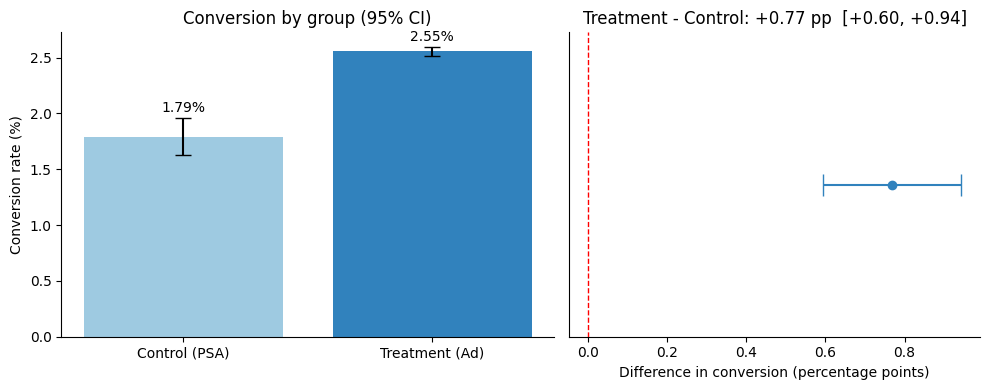

In [5]:
fig = plot_ab_rates(r)
fig.savefig(OUTPUTS / "ab_test_result.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Result in plain language

In [6]:
print(ab.interpret(r, "en"))
print()
print(ab.interpret(r, "tr"))

In the treatment group, conversion increased by 0.77 percentage points vs. control (1.79% -> 2.55%; relative change +43.1%, 95% CI [+30.6%, +57.8%]). The 95% CI for the difference is [+0.60, +0.94] pp, p < 0.0001; the result is statistically significant (Cohen's h = 0.053, effect size: negligible).

Treatment grubunda conversion, control'e göre 0.77 yüzde puan arttı (%1.79 → %2.55; göreli değişim %+43.1, %95 GA: [+30.6%, +57.8%]). Fark için %95 güven aralığı [+0.60, +0.94] pp, p < 0.0001; sonuç istatistiksel olarak anlamlı bulundu (Cohen's h = 0.053, etki büyüklüğü: ihmal edilebilir).


**Statistical vs. practical significance.** With hundreds of thousands of users, even a small difference is statistically significant. Cohen's h is small because baseline conversion is low (~2%), but a lift of this size can still be large *relatively* and valuable in revenue terms - judge it against campaign cost.

## 4. Power & sensitivity (what could this test detect?)

In [7]:
mde = ab.minimum_detectable_effect(r["conv_control"], r["n_control"], r["n_treatment"])
print(f"Minimum detectable effect (80% power, alpha=0.05): {mde*100:.2f} pp")
print(f"Users needed PER GROUP to detect the observed lift ({r['abs_diff']*100:.2f} pp): {ab.required_sample_size(r['conv_control'], abs(r['abs_diff'])):,}")

Minimum detectable effect (80% power, alpha=0.05): 0.25 pp
Users needed PER GROUP to detect the observed lift (0.77 pp): 5,631


## 5. Segment analysis (exploratory)
Many segments = many chances for a false positive, so p-values are **Bonferroni-adjusted**. (`total_ads` is measured *after* assignment, so we do not condition on it - that would bias the causal estimate.)

In [8]:
df["most_ads_day"] = pd.Categorical(df["most_ads_day"], ab.DAY_ORDER, ordered=True)
seg_day = ab.segment_analysis(df, "most_ads_day")
seg_day

,most_ads_day,n_control,n_treatment,conv_control,conv_treatment,abs_diff_pp,ci_low_pp,ci_high_pp,p_value,p_adj_bonferroni,significant_adj
0,Monday,3502,83571,0.0226,0.0332,1.0683,0.5617,1.5749,0.0005,0.0036,True
1,Tuesday,2907,74572,0.0144,0.0304,1.5992,1.1483,2.0502,0.0000,0.0000,True
2,Wednesday,3490,77418,0.0158,0.0254,0.9597,0.5319,1.3874,0.0004,0.0026,True
3,Thursday,3905,79077,0.0202,0.0216,0.1407,-0.3124,0.5937,0.5548,1.0000,False
4,Friday,3803,88805,0.0163,0.0225,0.6162,0.2021,1.0303,0.0116,0.0810,False
5,Saturday,2858,78802,0.0140,0.0213,0.7311,0.2888,1.1734,0.0075,0.0524,False
6,Sunday,3059,82332,0.0206,0.0246,0.4025,-0.1118,0.9168,0.1572,1.0000,False


In [9]:
seg_hour = ab.segment_analysis(df, "most_ads_hour")
seg_hour.sort_values("abs_diff_pp", ascending=False).head(5)

/Users/elifakbas/Desktop/Portfoy/Data Analystics/growth-funnel-analytics/notebooks/../src/ab_test.py:54: RuntimeWarning: divide by zero encountered in divide
  rel_b = pt_b / pc_b - 1


,most_ads_hour,n_control,n_treatment,conv_control,conv_treatment,abs_diff_pp,ci_low_pp,ci_high_pp,p_value,p_adj_bonferroni,significant_adj
12,20,1077,27846,0.0176,0.0303,1.2632,0.4516,2.0748,0.0168,0.2680,False
6,14,1869,43779,0.0161,0.0286,1.2524,0.6617,1.8431,0.0013,0.0212,True
14,22,917,25515,0.0164,0.0265,1.0097,0.1654,1.8540,0.0595,0.9528,False
15,23,619,19547,0.0129,0.0230,1.0046,0.0904,1.9188,0.0982,1.0000,False
0,8,659,16968,0.0106,0.0199,0.9239,0.1135,1.7342,0.0925,1.0000,False
